 # Task-1 (Week-5)

**Date** :- (02-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Fine-tune gradient boosting models, such as LightGBM and CatBoost, with custom loss functions and learning rate schedules to improve prediction precision in complex applicant datasets..

In [14]:
# Import Library 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import lightgbm as lgb
from catboost import CatBoostClassifier

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,  
    confusion_matrix
)

from scipy.special import expit
import math

In [15]:
# Load the Dataset 

df = pd.read_csv("Admission_Prediction.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1000, 17)


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,03-01-2022,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,09-01-2022,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,12-01-2022,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,13-01-2022,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,14-01-2022,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170


In [16]:
# Check the Columns

print(df.columns.tolist())

['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status', 'Duration_Months', 'Dropout_Event', 'Dropout-free survival']


In [29]:
# Data preprocessing

# Remove unnecessary columns
df = df.drop(
    columns=[
        "Serial No.",
        "Chance of Admit",
        "Application_Date",
        "Year",
        "Duration_Months",
        "Dropout_Event",
        "Dropout-free survival",
        "Survival_Data_Note"
    ],
    errors="ignore"
)

# Clean target labels
df["Admission Status"] = (
    df["Admission Status"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Keep only Accepted and Rejected
df = df[
    df["Admission Status"].isin(["Accepted", "Rejected"])
].copy()

# Separate features and target
X = df.drop("Admission Status", axis=1)

y = df["Admission Status"].map({
    "Rejected": 0,
    "Accepted": 1
})

print(X.shape)
print(y.value_counts())

(1000, 9)
Admission Status
0    565
1    435
Name: count, dtype: int64


In [30]:
# Identify numerical and categorical features

numeric_features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

categorical_features = [
    "University_Name",
    "region"
]


In [31]:
# Define preprocessing steps
# The preprocessor will be fitted only on the training data in the next cell.

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


In [32]:
# Split the original data before preprocessing to prevent data leakage
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit preprocessing only on training data
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (800, 62)
Testing Data: (200, 62)


In [33]:
# Create a custom loss function

# Calculate class weights
class_weights = {
    0: len(y_train) / (2 * (y_train == 0).sum()),
    1: len(y_train) / (2 * (y_train == 1).sum())
}

print("Class Weights:", class_weights)

Class Weights: {0: np.float64(0.8849557522123894), 1: np.float64(1.1494252873563218)}


In [34]:
# Implement and fine-tune LightGBM

def weighted_logloss(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=int)

    probabilities = expit(y_pred)

    weights = np.where(
        y_true == 1,
        class_weights[1],
        class_weights[0]
    )

    gradients = (
        probabilities - y_true
    ) * weights

    hessians = (
        probabilities * (1 - probabilities)
    ) * weights

    return gradients, hessians

In [35]:
# Train the LightGBM model with a decreasing learning rate schedule

lgb_model = lgb.LGBMClassifier(
    objective=weighted_logloss,
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=20,
    min_child_samples=10,
    reg_lambda=1.0,
    random_state=42,
    verbosity=-1
)

# Learning rate schedule
lr_schedule = lgb.reset_parameter(
    learning_rate=lambda iteration:
        0.05 if iteration < 100
        else 0.02 if iteration < 200
        else 0.01
)

# Train model
lgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[
        lr_schedule,
        lgb.early_stopping(30),
        lgb.log_evaluation(50)
    ]
)

print("LightGBM Training Completed!")

Training until validation scores don't improve for 30 rounds
Early stopping, best iteration is:
[7]	valid_0's binary_logloss: 5.4462
LightGBM Training Completed!


In [36]:
# CatBoost uses built-in Logloss with class weights.
# The custom weighted objective is implemented in the LightGBM section.
catboost_class_weights = [class_weights[0], class_weights[1]]
print("CatBoost class weights:", catboost_class_weights)


CatBoost class weights: [np.float64(0.8849557522123894), np.float64(1.1494252873563218)]


In [37]:
# Train CatBoost in three consecutive learning-rate stages
# This avoids the Numba error from a Python-defined CatBoost custom objective.

cat_model = None
learning_rates = [0.05, 0.02, 0.01]

for stage, lr in enumerate(learning_rates, start=1):
    stage_model = CatBoostClassifier(
        iterations=100,
        learning_rate=lr,
        depth=5,
        loss_function="Logloss",
        eval_metric="Logloss",
        class_weights=catboost_class_weights,
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )

    stage_model.fit(
        X_train,
        y_train,
        init_model=cat_model
    )

    cat_model = stage_model
    print(f"Completed CatBoost stage {stage}: learning_rate={lr}")

print("CatBoost Training Completed!")
print("Total CatBoost trees:", cat_model.tree_count_)


Completed CatBoost stage 1: learning_rate=0.05
Completed CatBoost stage 2: learning_rate=0.02
Completed CatBoost stage 3: learning_rate=0.01
CatBoost Training Completed!
Total CatBoost trees: 300


In [38]:
# Evaluate both models

# With a custom LightGBM objective, predict() returns raw scores (margins).
# A raw score >= 0 corresponds to probability >= 0.5.
lgb_raw_scores = lgb_model.predict(X_test)
lgb_pred = (lgb_raw_scores >= 0).astype(int)

# CatBoost returns class labels
cat_pred = np.asarray(cat_model.predict(X_test)).ravel().astype(int)

def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0)
    }

lgb_results = evaluate_model("LightGBM", y_test, lgb_pred)
cat_results = evaluate_model("CatBoost", y_test, cat_pred)

results_df = pd.DataFrame([lgb_results, cat_results])
print(results_df)


      Model  Accuracy  Precision    Recall  F1 Score
0  LightGBM     0.675   0.617021  0.666667  0.640884
1  CatBoost     0.630   0.578313  0.551724  0.564706


d:\photo\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
d:\photo\Anaconda\Lib\site-packages\lightgbm\sklearn.py:1638: UserWarning: Cannot compute class probabilities or labels due to the usage of customized objective function.
Returning raw scores instead.
  _log_warning(


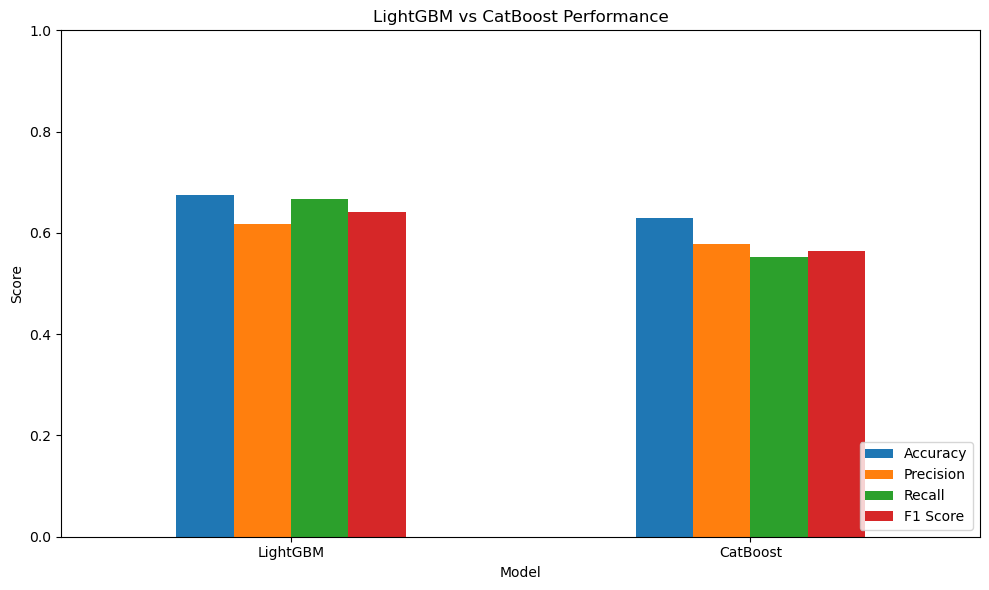

In [39]:
# Compare model performance

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("LightGBM vs CatBoost Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [40]:
# Classification reports

print("LIGHTGBM CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        lgb_pred,
        target_names=["Rejected", "Accepted"],
        zero_division=0
    )
)

print("CATBOOST CLASSIFICATION REPORT")

print(
    classification_report(
        y_test,
        cat_pred,
        target_names=["Rejected", "Accepted"],
        zero_division=0
    )
)

LIGHTGBM CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Rejected       0.73      0.68      0.70       113
    Accepted       0.62      0.67      0.64        87

    accuracy                           0.68       200
   macro avg       0.67      0.67      0.67       200
weighted avg       0.68      0.68      0.68       200

CATBOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Rejected       0.67      0.69      0.68       113
    Accepted       0.58      0.55      0.56        87

    accuracy                           0.63       200
   macro avg       0.62      0.62      0.62       200
weighted avg       0.63      0.63      0.63       200



In [41]:
# Select the best model

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: LightGBM
